# Demonstrate autodiff through advection and diffusion

In this notebook, we demonstrate autodiff through the PyTorch operators provided by the _tridiag_ package.

We will recreate an entire simulation of tracer sinking (advection _in_ the water) and diffusion due to turbulent diffusion. Doing so, we will use the hydrodynamic output of GOTM as input for our simulation. Then, we will use the autodiff functionality of PyTorch for demonstrating the time evolution of gradients.

### Simulation setup

At first, we import the required modules:

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mc
import torch
from torch.func import jacfwd
from tensordict import TensorDict

from marinade.gotm.gotm import TracerSimulationOperator
from marinade.fabm.passive_model import PassiveModel

Now, we set up some variables needed for the advection and diffusion simulation:

In [ ]:
# define axes:
dt = 60.0
nlev = 110
t = torch.arange(2401) * dt
z = torch.linspace(-109.5, -0.5, 110)

# define initial state and forcing conditions:
init_state = (torch.full((1, 1, 110), 8.15, dtype=torch.float64))
h = torch.ones((1, 2401, 1, 110), dtype=torch.float64)
t_idx, z_idx = torch.meshgrid(torch.arange(0, 2401, 1), torch.arange(0, 110, 1), indexing='ij')
nu = torch.sqrt(z_idx*(109-z_idx))*torch.tanh(t_idx/2000)*0.155*1/(1+torch.exp(-(0.0005*t_idx**2 - 20*z_idx)/150))*torch.exp(-(z_idx-25)**2/(2*40**2)) / 50
nu.unsqueeze_(0).unsqueeze_(2)
scheme = "p2_pdm"
model = PassiveModel(torch.tensor(-86.4/(60**2*24), dtype=torch.float64))

# define the operator:
transport_operator = TracerSimulationOperator("neumann", "neumann", 0., 0., "flux", "flux", 0., 0., "p2_pdm", method_tridiag="paracr", model=model)

### Simulation and computation of "area of influence"

We now compute the tracer concentration time series by applying the advection and diffusion operators.

In [ ]:
nlvl = 110
time = h.shape[1]
init_simulation = init_state.requires_grad_()
simulation = [init_simulation]
for i in range(time-1):
    solution = transport_operator(simulation[-1], dt, h[:, i], nu[:, i])
    solution.retain_grad()
    simulation.append(solution)
    simulation_list = simulation
simulation = torch.stack(simulation, dim=1)  # result: simulation[time, tracer, z]

Note that we set _solution.retain_grad()_ for all intermediate concentrations. This enables us to compute and explicitly visualize a gradient time series. Specifically, we compute the derivative of the concentration in the central cell of our simulation with respect to all other cells by backpropagating from the central cell:

In [ ]:
if not init_simulation.grad is None:
    init_simulation.grad.zero_()
    for _sim in simulation_list:
        _sim.grad.zero_()
simulation[:, len(t)//2, :, len(z)//2].backward(retain_graph=True)

We can now plot the time series:

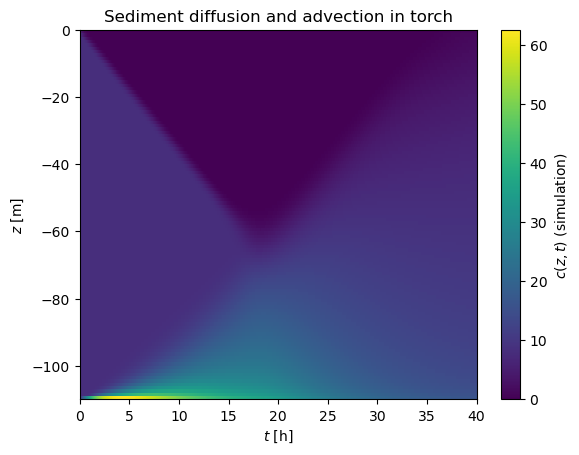

In [ ]:
plt.pcolormesh(t / 3600, z, simulation.detach().squeeze().T)
plt.xlabel('$t$ [h]')
plt.ylabel('$z$ [m]')
plt.title('Sediment diffusion and advection in torch')
plt.colorbar(label='$c(z,t)$ (simulation)')
plt.show()

We see that, at the beginning of the simulation, the sinking of the tracer dominates and it accumulates on the bottom. Later on, we see that the turbulent diffusivity becomes stronger and the concentration diffuses through the fluid.

Now, we have a look at the gradient time series:

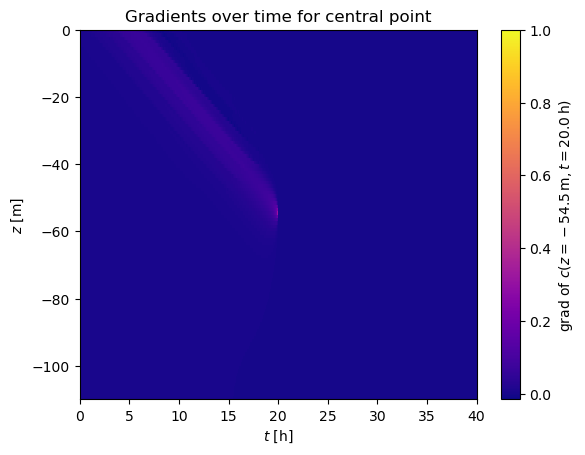

In [ ]:
grad_list = [_sim.grad for _sim in simulation_list]
grad_list_stacked = torch.stack(grad_list, dim=1)
plt.pcolormesh(t / 3600, z, grad_list_stacked.squeeze().T, vmax=None, shading='nearest', cmap='plasma')
plt.colorbar(label=f'grad of $c(z={z[len(z)//2]}\\,\\text{{m}},t={t[len(t)//2]/3600}\\,\\text{{h}})$')
plt.xlabel('$t$ [h]')
plt.ylabel('$z$ [m]')
plt.title('Gradients over time for central point')
plt.show()

### Sensitivity of simulation output to sinking velocity

We can use automatic differentiation to compute the sensitivity of the simulation to the sinking velocity. For this, we use forward-mode autodiff:

In [ ]:
def f(ws):
    model.update_parameters(TensorDict({'ws': -ws}))
    # return simulation * ws, simulation
    _init_state = (torch.full((1, 1, 110), 8.15, dtype=torch.float64))
    _simulation = [_init_state]
    for i in range(time-1):
        _simulation.append(transport_operator(_simulation[-1], dt, h[:, i], nu[:, i]))
    _simulation = torch.stack(_simulation, dim=1)  # result: _simulation[time, tracer, z]
    return _simulation, _simulation

ws = torch.tensor([[[86.4/(60**2*24)]]], dtype=torch.float64)
jac, simulation = jacfwd(f, has_aux=True)(ws)

Note that we define the sinking velocity as a positive parameter.

We can now visualize the sensitivity:

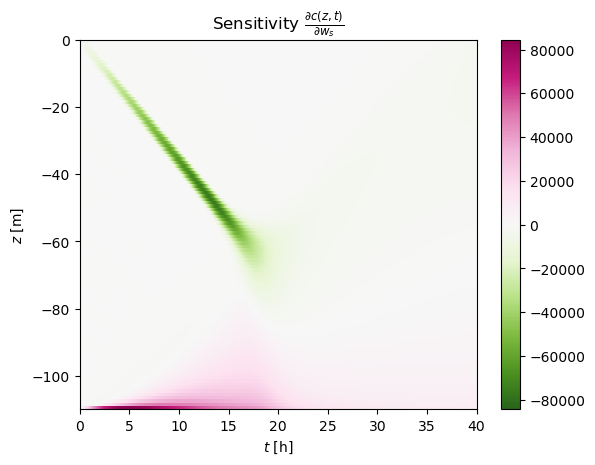

In [ ]:
plt.pcolormesh(t / 3600, z, jac.detach().squeeze().T, norm=mc.CenteredNorm(), cmap='PiYG_r', shading='nearest')
plt.colorbar()
plt.xlabel('$t$ [h]')
plt.ylabel('$z$ [m]')
plt.title(r'Sensitivity $\frac{\partial c(z,t)}{\partial w_s}$')
plt.show()

A higher sinking velocity leads to higher concentrations at the bottom of the water column, and it will shift the sinking profile to the lower layers.